In [1]:
from google.colab import files
uploaded = files.upload()

Saving bbc-text.csv to bbc-text.csv


In [2]:
import os
print(os.path.exists('/content/bbc-text.csv'))

True


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [5]:
df = pd.read_csv('/content/bbc-text.csv')
df.head()

,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


In [6]:
print("Dataset shape:", df.shape)
print("\nCategories:")
print(df['category'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset shape: (2225, 2)

Categories:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Missing Values:
category    0
text        0
dtype: int64


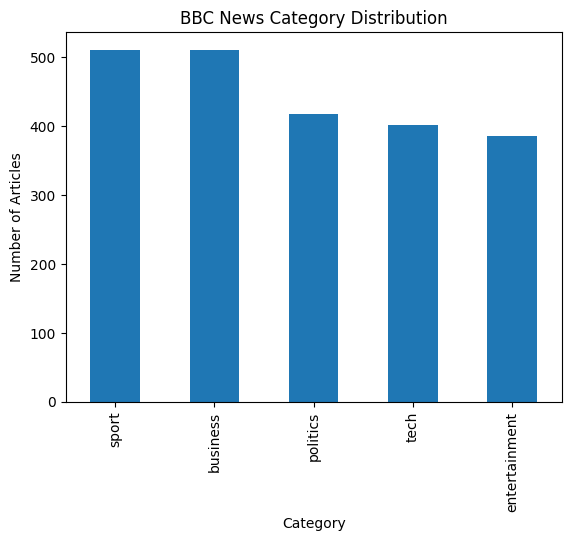

In [7]:
df['category'].value_counts().plot(kind='bar')

plt.title('BBC News Category Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Articles')
plt.show()

In [8]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [9]:
def preprocess_text(text):

    text = text.lower()

    text = re.sub(r'[^a-z\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [10]:
df['clean_text'] = df['text'].apply(preprocess_text)

df[['text', 'clean_text']].head()

,text,clean_text
0,tv future in the hands of viewers with home th...,tv future hand viewer home theatre system plas...
1,worldcom boss left books alone former worldc...,worldcom bos left book alone former worldcom b...
2,tigers wary of farrell gamble leicester say ...,tiger wary farrell gamble leicester say rushed...
3,yeading face newcastle in fa cup premiership s...,yeading face newcastle fa cup premiership side...
4,ocean s twelve raids box office ocean s twelve...,ocean twelve raid box office ocean twelve crim...


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['category'],
    test_size=0.20,
    random_state=42,
    stratify=df['category']
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1780
Testing samples: 445


In [12]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (1780, 5000)
Testing shape: (445, 5000)


In [13]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

In [14]:
print("Multinomial Naive Bayes")
print()

print("Accuracy:",
      accuracy_score(y_test, nb_pred))

print(classification_report(y_test, nb_pred))

Multinomial Naive Bayes

Accuracy: 0.9865168539325843
               precision    recall  f1-score   support

     business       0.99      0.96      0.98       102
entertainment       0.99      0.99      0.99        77
     politics       0.97      1.00      0.98        84
        sport       1.00      1.00      1.00       102
         tech       0.99      0.99      0.99        80

     accuracy                           0.99       445
    macro avg       0.99      0.99      0.99       445
 weighted avg       0.99      0.99      0.99       445



In [15]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

In [16]:
print("Logistic Regression")
print()

print("Accuracy:",
      accuracy_score(y_test, lr_pred))

print(classification_report(y_test, lr_pred))

Logistic Regression

Accuracy: 0.9797752808988764
               precision    recall  f1-score   support

     business       0.98      0.97      0.98       102
entertainment       0.96      1.00      0.98        77
     politics       0.98      0.96      0.97        84
        sport       1.00      1.00      1.00       102
         tech       0.97      0.96      0.97        80

     accuracy                           0.98       445
    macro avg       0.98      0.98      0.98       445
 weighted avg       0.98      0.98      0.98       445



In [17]:
results = pd.DataFrame({
    'Model': [
        'Multinomial Naive Bayes',
        'Logistic Regression'
    ],

    'Accuracy': [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, lr_pred)
    ],

    'Precision': [
        precision_score(
            y_test,
            nb_pred,
            average='macro',
            zero_division=0
        ),

        precision_score(
            y_test,
            lr_pred,
            average='macro',
            zero_division=0
        )
    ],

    'Recall': [
        recall_score(
            y_test,
            nb_pred,
            average='macro',
            zero_division=0
        ),

        recall_score(
            y_test,
            lr_pred,
            average='macro',
            zero_division=0
        )
    ],

    'F1-score': [
        f1_score(
            y_test,
            nb_pred,
            average='macro',
            zero_division=0
        ),

        f1_score(
            y_test,
            lr_pred,
            average='macro',
            zero_division=0
        )
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,0.986517,0.985986,0.987059,0.986419
1,Logistic Regression,0.979775,0.978657,0.979475,0.978975


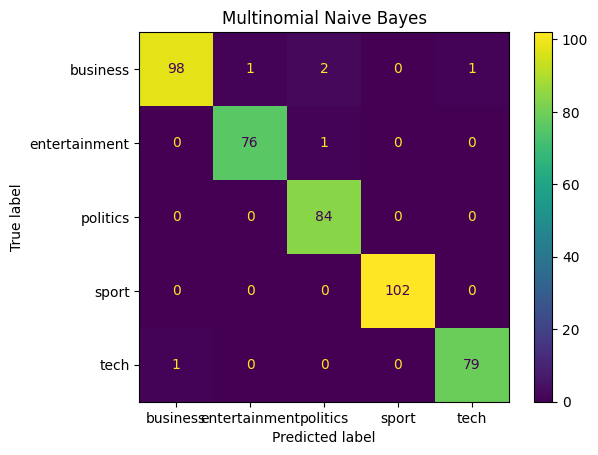

In [18]:
cm_nb = confusion_matrix(
    y_test,
    nb_pred,
    labels=nb_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=nb_model.classes_
)

disp.plot()

plt.title('Multinomial Naive Bayes')
plt.show()

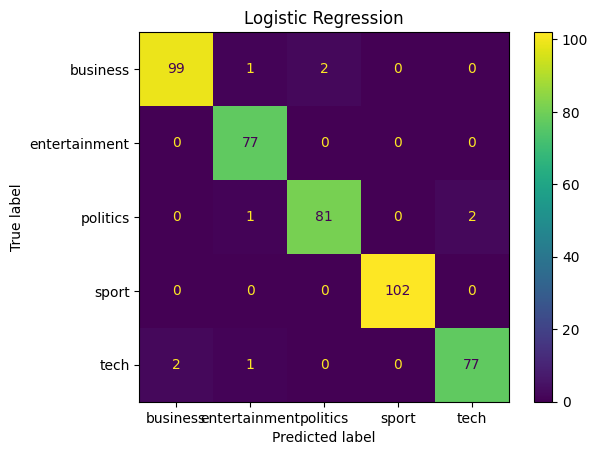

In [19]:
cm_lr = confusion_matrix(
    y_test,
    lr_pred,
    labels=lr_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=lr_model.classes_
)

disp.plot()

plt.title('Logistic Regression')
plt.show()

In [20]:
nb_accuracy = accuracy_score(y_test, nb_pred)
lr_accuracy = accuracy_score(y_test, lr_pred)

if lr_accuracy >= nb_accuracy:
    best_model = lr_model
    best_pred = lr_pred
    best_model_name = 'Logistic Regression'
else:
    best_model = nb_model
    best_pred = nb_pred
    best_model_name = 'Multinomial Naive Bayes'

print("Best Model:", best_model_name)

Best Model: Multinomial Naive Bayes


In [21]:
error_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'actual': y_test.reset_index(drop=True),
    'predicted': best_pred
})

errors = error_df[
    error_df['actual'] != error_df['predicted']
]

print("Number of incorrect predictions:", len(errors))

errors.head(10)

Number of incorrect predictions: 6


,text,actual,predicted
4,saudi ministry employ woman woman employed sau...,business,politics
17,tv show unites angolan family angolan family a...,entertainment,politics
20,call overhaul uk state pension uk pension syst...,business,politics
60,card fraudsters targeting web new safeguard cr...,business,tech
78,china ripe medium explosion asia set drive glo...,tech,business
340,mcdonald sponsor mtv show mcdonald world large...,business,entertainment


In [22]:
errors.groupby(
    ['actual', 'predicted']
).size().sort_values(
    ascending=False
).head(10)

actual         predicted    
business       politics         2
               entertainment    1
               tech             1
entertainment  politics         1
tech           business         1
dtype: int64

In [23]:
def predict_news_topic(article):

    clean_article = preprocess_text(article)

    article_tfidf = tfidf.transform(
        [clean_article]
    )

    prediction = best_model.predict(
        article_tfidf
    )

    return prediction[0]

In [24]:
article = """
The football team won the championship
after scoring three goals in the final match.
"""

print(
    "Predicted Topic:",
    predict_news_topic(article)
)

Predicted Topic: sport
